pip install numpy scipy pandas scikit-learn jupyter matplotlib

## Ответы на вопросы

#### Предложите новый метод инициализации центроидов кластеров для метода k-средних. Перечислите преимущества и недостатки метода Форджи, метода случайного разбиения и вашего собственного метода инициализации.

**Мой метод:**\
Нам даны данные, мы выделяем основную массу (например, 90%) и визуально очерчиваем их в прямоугольник. Далее мы этот прямоугольник делим на k равных частей, находя приблизительный центр каждой фигуры, мы находим центроид. Каждый объект относим к кластером по критерию расстояние. 

**Метод Форджи (Forgy)**\
Преимущества:
- Простой и быстрый.
- Центроиды гарантированно являются реальными точками данных.
- Хорошо работает, если кластеры компактные и не слишком сильно перекрываются.

Недостатки:
- Чувствителен к выбросам.
- Может привести к пустым кластерам (если случайно центроид - это выброс).
- Разные запуски дают разные результаты.

**Метод случайного разбиения (Random Partition)**\
Преимущества:
- Центроиды автоматически находятся в центре случайных групп.
- Меньше шансов получить пустой кластер, чем в Forgy.
- Лучше работает на несбалансированных данных.

Недостатки:
- Вычислительно дороже (нужно сначала разбить, потом посчитать средние).
- Начальные центроиды могут быть в пустоте из-за случайного присвоения меток.
- При неудачном случайном разбиении может потребоватся долгий перебор.

#### Опишите, как можно использовать кластеризацию для ускорения работы модели KNN?

Изначально KNN очень медленный метод, можно сначала разделить данные на кластеры по ближайшим центроидам, например, 1 кластер - 10% от всей выборки. И тогда в KNN сначала искать обший кластер из 10%, а уже потом внутри него искать локальный. Этот алгоритм позволяет ускорить метод в
$$\frac{\text{все точки}}{\text{среднее кол-во точек в кластере}} \text{  раз}.$$

## Подготовка данных

In [1]:
import pandas as pd
import numpy as np
from collections import Counter
from scipy.spatial.distance import cdist
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import Lasso
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import NearestNeighbors
from sklearn.mixture import GaussianMixture
from mpl_toolkits.mplot3d import Axes3D
import time
from sklearn.ensemble  import RandomForestRegressor

In [2]:
df = pd.read_json("data/train.json")

In [3]:
df.info()

<class 'pandas.DataFrame'>
Index: 49352 entries, 4 to 124009
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   bathrooms        49352 non-null  float64
 1   bedrooms         49352 non-null  int64  
 2   building_id      49352 non-null  str    
 3   created          49352 non-null  str    
 4   description      49352 non-null  str    
 5   display_address  49352 non-null  str    
 6   features         49352 non-null  object 
 7   latitude         49352 non-null  float64
 8   listing_id       49352 non-null  int64  
 9   longitude        49352 non-null  float64
 10  manager_id       49352 non-null  str    
 11  photos           49352 non-null  object 
 12  price            49352 non-null  int64  
 13  street_address   49352 non-null  str    
 14  interest_level   49352 non-null  str    
dtypes: float64(3), int64(3), object(2), str(7)
memory usage: 6.0+ MB


In [4]:
# pd.set_option('display.max_columns', None)
values = df['interest_level'].unique()
values

<StringArray>
['medium', 'low', 'high']
Length: 3, dtype: str

In [5]:
df['interest_level'] = df['interest_level'].map({'medium': 1, 'low': 0, 'high': 2})

In [6]:
col_features = df['features'].astype(str).str.replace(r'[\[\]\'\"]','', regex=True)
col_features = col_features.str.strip().str.split(", ")

names_features = list()
for row in col_features:
    for i in row:
        if i != "":
            names_features.append(i.title())

In [7]:
features = Counter(names_features)
top_features = features.most_common(20)
top_features

[('Elevator', 26273),
 ('Hardwood Floors', 23558),
 ('Cats Allowed', 23540),
 ('Dogs Allowed', 22035),
 ('Doorman', 20967),
 ('Dishwasher', 20806),
 ('Laundry In Building', 18944),
 ('No Fee', 18079),
 ('Fitness Center', 13257),
 ('Laundry In Unit', 9435),
 ('Pre-War', 9149),
 ('Roof Deck', 6555),
 ('Outdoor Space', 5270),
 ('Dining Room', 5150),
 ('High Speed Internet', 4299),
 ('Balcony', 3058),
 ('Swimming Pool', 2730),
 ('New Construction', 2608),
 ('Terrace', 2313),
 ('Exclusive', 2167)]

In [8]:
data = pd.DataFrame()
data[['latitude', 'longitude', 'interest_level','bedrooms', 'bathrooms', 'price']] = df[['latitude', 'longitude', 'interest_level','bedrooms', 'bathrooms', 'price']]
for col, n in top_features:
    data[col] = df['features'].apply(lambda x: 1 if col in x else 0)

In [9]:
q1 = data['price'].quantile(0.01)
q99 = data['price'].quantile(0.99)
data = data[(data['price'] > q1) & (data['price'] < q99)]

In [10]:
X = data.drop(columns='price')
y = data['price'].copy()
X_train_temp_clusters, X_test_temp_clusters, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=21)

X_train_for_clusters = X_train_temp_clusters[['latitude', 'longitude']]
X_test_for_clusters = X_test_temp_clusters[['latitude', 'longitude']]

feature_names = X_train_temp_clusters.drop(columns=['latitude', 'longitude']).columns
scaler = MinMaxScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train_temp_clusters.drop(columns=['latitude', 'longitude'])), columns=feature_names)
X_test = pd.DataFrame(scaler.transform(X_test_temp_clusters.drop(columns=['latitude', 'longitude'])), columns=feature_names)

## Реализация кластеризации

### Требуемые функции

In [11]:
def metrics(result_MAE, result_RMSE, result_r2, y_train, score_train, y_test, score_test, name):
    result_MAE.loc[len(result_MAE)] = {
        'model': name,
        'train': mean_absolute_error(y_train, score_train),
        'test': mean_absolute_error(y_test, score_test)
    }
    
    result_RMSE.loc[len(result_RMSE)] = {
        'model': name,
        'train': mean_squared_error(y_train, score_train) ** 0.5,
        'test': mean_squared_error(y_test, score_test) ** 0.5
    }
    
    result_r2.loc[len(result_r2)] = {
        'model': name,
        'train': r2_score(y_train, score_train),
        'test': r2_score(y_test, score_test)
    }
    return result_MAE, result_RMSE, result_r2

In [12]:
result_MAE = pd.DataFrame(columns=['model', 'train','test'])
result_RMSE = pd.DataFrame(columns=['model', 'train','test'])
result_r2 = pd.DataFrame(columns=['model', 'train','test'])

result_sil = pd.DataFrame(columns=['model', 'train','test'])
result_time = pd.DataFrame(columns=['model', 'time'])

In [13]:
def silsil(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test, result_sil, name):
    sil_train = silhouette_score(X_train_for_clusters, pred_train)
    print(f"Оценка силуэта (обучение): {sil_train}")
    
    sil_test = silhouette_score(X_test_for_clusters, pred_test)
    print(f"Оценка силуэта (тест): {sil_test}")
    
    result_sil.loc[len(result_sil)] = {
        'model': name,
        'train': sil_train,
        'test': sil_test
    }
    return result_sil

In [14]:
def drow_for_longitude_latitude(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test, name):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8))
    
    sc1 = ax1.scatter(X_train_for_clusters.iloc[:, 0], X_train_for_clusters.iloc[:, 1],
                      c=pred_train, s=10, cmap='Set2')
    ax1.set_ylabel('longitude')
    ax1.set_xlabel('latitude')
    ax1.set_title(f'Прогноз {name} train')
    ax1.legend(*sc1.legend_elements(),
               title='Interest level',
               loc='upper right')
    ax1.set_ylim(-74.05, -73.85)
    ax1.set_xlim(40.65, 40.85)
    
    sc2 = ax2.scatter(X_test_for_clusters.iloc[:, 0], X_test_for_clusters.iloc[:, 1], c=pred_test, s=10, cmap='Set2')
    ax2.set_ylabel('longitude')
    ax2.set_xlabel('latitude')
    ax2.set_title(f'Прогноз {name} test')
    ax2.legend(*sc2.legend_elements(),
               title='Interest level',
               loc='upper right')
    ax2.set_ylim(-74.05, -73.85)
    ax2.set_xlim(40.65, 40.85)
    
    fig.suptitle(f'Сравнение {name}', fontsize=20)
    plt.tight_layout()
    plt.show()

In [15]:
def lasso_predict(X_train, X_test, y_train):
    feature_names = X_train.columns
    
    scaler = MinMaxScaler()
    X_train_temp = X_train.copy()
    X_test_temp = X_test.copy()
    X_train = pd.DataFrame(scaler.fit_transform(X_train_temp), columns=feature_names)
    X_test = pd.DataFrame(scaler.transform(X_test_temp), columns=feature_names)
    
    lasso = Lasso(random_state=21)
    lasso.fit(X_train, y_train)
    lasso_pred_train = lasso.predict(X_train)
    lasso_pred_test = lasso.predict(X_test)
    
    columns_name = X_train.columns
    feature_importance = pd.DataFrame()
    feature_importance['name'] = columns_name
    feature_importance['imp'] = abs(lasso.coef_)
    feature_importance = feature_importance.sort_values('imp')
    return feature_importance, lasso_pred_train, lasso_pred_test

In [16]:
def rf_predict(X_train, X_test, y_train):
    sl = RandomForestRegressor(random_state=21)
    sl.fit(X_train, y_train)
    
    pred_train = sl.predict(X_train)
    if X_test is not None: pred_test = sl.predict(X_test)
    else: pred_test = None
    feature_importance = pd.DataFrame({
        'name': X_train.columns,
        'imp': sl.feature_importances_
    }).sort_values('imp', ascending=True)

    return feature_importance, pred_train, pred_test

In [17]:
lasso = Lasso(random_state=21)
lasso.fit(X_train, y_train)
lasso_pred_train = lasso.predict(X_train)
lasso_pred_test = lasso.predict(X_test)

In [18]:
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'Изначальный')

### KMeans

#### Как работает

Алгоритм кластеризации, который группирует объекты вокруг центроидов, минимизируя сумму квадратов расстояний до них. \
Алгоритм:
1. Инициализация центроидов (Forgy):
- Выбираем случайные K точек из данных
- Они становятся начальными центрами кластеров
2. Повторяем, пока центроиды не перестанут двигаться:
- Шаг назначения: Для каждой точки находим ближайший центроид (по квадрату евклидова расстояния) и присваиваем метку этого кластера
- Шаг обновления: Пересчитываем центроиды как среднее арифметическое всех точек в каждом кластере (если кластер пуст — выбираем случайную точку)
- Считаем инерцию — сумму квадратов расстояний от всех точек до их центроидов
- Если инерция изменилась меньше, чем tol — останавливаемся
3. Точки, отнесённые к одному центроиду, составляют кластер

#### Код

In [19]:
class KMeansClustering:
    def __init__(self, n_clusters=8, max_iter=300, tol=0.001, random_state=0):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol # мин расстояние для остановки изменения центроидов
        self.random_state = random_state
        self.cluster_centers_ = None
        self.inertia_ = None # сумма квадратов расстояний от т. до центроида
        self.labels_ = None

    def _init_centroids_forgy(self, X):
        # рандомный выобор точек
        np.random.seed(self.random_state)
        n_samples = X.shape[0]
        indices = np.random.choice(n_samples, self.n_clusters, replace=False)
        return X[indices].copy()

    def fit(self, X):
        X = X.values
        n_samples, n_features = X.shape
        self.cluster_centers_ = self._init_centroids_forgy(X)
        self.inertia_ = float('inf')
        
        for iteration in range(self.max_iter):
            # вычисляем расстояние до каждого центроида и выбираем минимальное + считаем инерцию
            distances = cdist(X, self.cluster_centers_, metric='sqeuclidean')
            labels = np.argmin(distances, axis=1)
            new_inertia = np.sum(np.min(distances, axis=1))
            new_centers = np.zeros((self.n_clusters, n_features))

            # пересчитываем центроиды для каждого кластера
            for k in range(self.n_clusters):
                mask = (labels == k)
                if np.any(mask):
                    new_centers[k] = np.mean(X[mask], axis=0)
                else:
                    new_centers[k] = X[np.random.choice(n_samples)]
            # проверка на итерации
            if abs(new_inertia - self.inertia_) < self.tol:
                self.inertia_ = new_inertia
                self.cluster_centers_ = new_centers
                break
                
            self.inertia_ = new_inertia
            self.cluster_centers_ = new_centers
        
        self.labels_ = labels
        return self

    def predict(self, X):
        X = X.values
        distances = cdist(X, self.cluster_centers_, metric='sqeuclidean')
        return np.argmin(distances, axis=1)

In [20]:
start = time.time()
my_kmeans = KMeansClustering(n_clusters=30, random_state=42)
my_kmeans.fit(X_train_for_clusters)
pred_train = my_kmeans.predict(X_train_for_clusters)
pred_test = my_kmeans.predict(X_test_for_clusters)
end = time.time()
print(f"My KMeans: {end - start:.5f} сек")
result_time.loc[len(result_time)] = {
        'model': 'My KMeans',
        'time': round(end - start, 5)
    }

My KMeans: 0.25140 сек


In [21]:
distortion = my_kmeans.inertia_
print(f"Искажение (инерция): {distortion}")

result_sil = silsil(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test, result_sil, 'My KMeans')

Искажение (инерция): 21.29814951932142
Оценка силуэта (обучение): 0.4090490471489339
Оценка силуэта (тест): 0.40967457162189747


Искажение — это сумма квадратов расстояний от каждой точки до центроида своего кластера. *(нужно смотреть на изменение)*\
Силуэт показывает, насколько каждый объект "похож" на свой кластер и "отличается" от соседних кластеров. *(1 - идеально)*

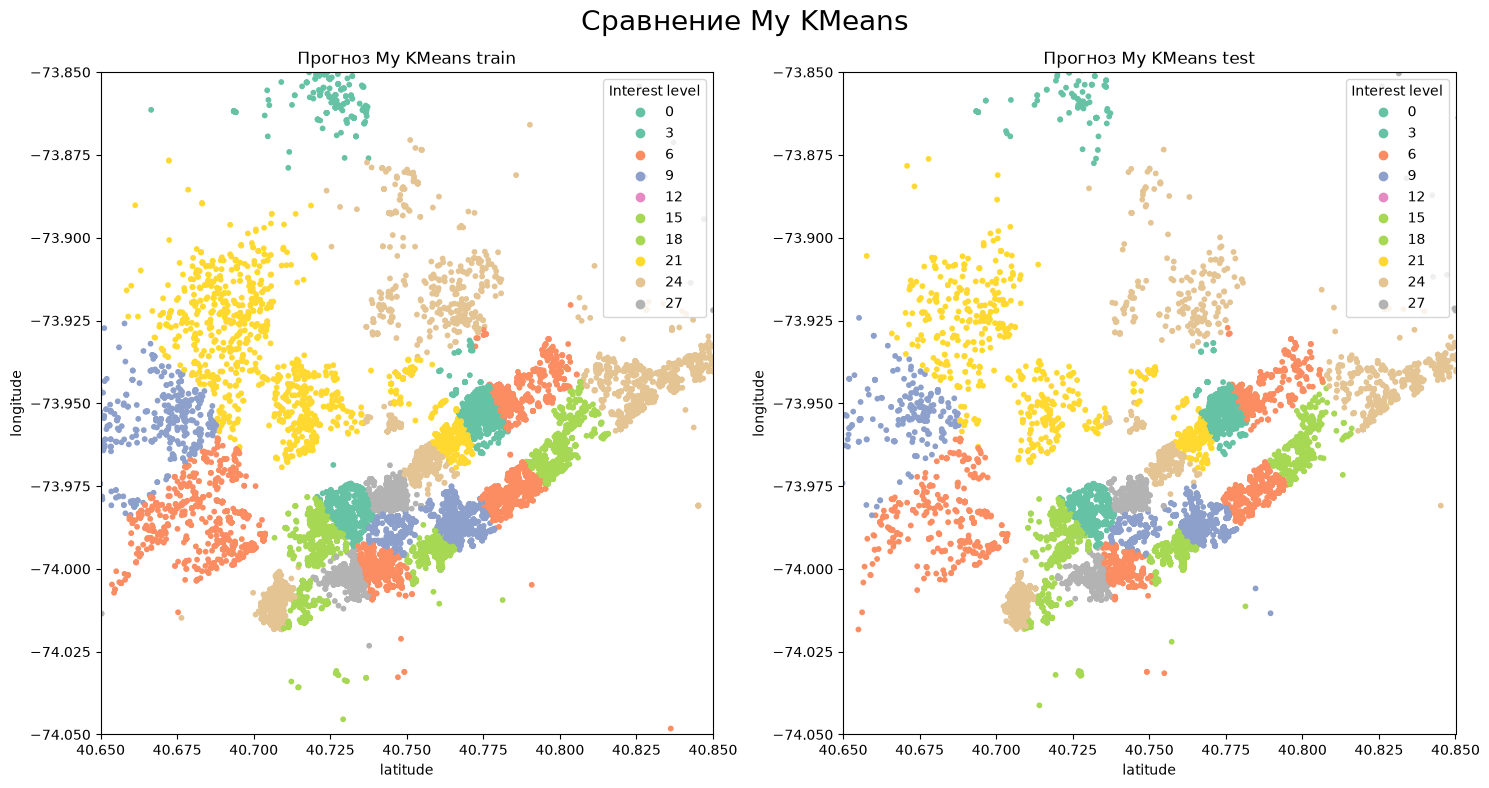

In [22]:
drow_for_longitude_latitude(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test, 'My KMeans')

In [23]:
X_train['cluster'] = pred_train
X_test['cluster'] = pred_test

In [24]:
feature_importance, lasso_pred_train, lasso_pred_test = lasso_predict(X_train, X_test, y_train)
feature_importance

,name,imp
20,New Construction,0.000000
18,Balcony,14.949536
15,Outdoor Space,19.896081
5,Cats Allowed,28.286429
13,Pre-War,30.761909
22,Exclusive,35.303527
19,Swimming Pool,43.193346
10,No Fee,66.209590
4,Hardwood Floors,100.361853
6,Dogs Allowed,107.319638


In [25]:
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'Мой Kmeans')

In [26]:
start = time.time()
cluster_model = KMeans(n_clusters=30, random_state=42)
cluster_model.fit(X_train_for_clusters)
pred_train = cluster_model.predict(X_train_for_clusters)
pred_test = cluster_model.predict(X_test_for_clusters)
end = time.time()
print(f"KMeans: {end - start:.5f} сек")

result_time.loc[len(result_time)] = {
        'model': 'KMeans',
        'time': round(end - start, 5)
    }

KMeans: 0.17227 сек


In [27]:
distortion = cluster_model.inertia_
print(f"Искажение (инерция): {distortion}")

result_sil = silsil(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test, result_sil, 'KMeans')

Искажение (инерция): 4.546754081998236
Оценка силуэта (обучение): 0.4512403309538485
Оценка силуэта (тест): 0.4570180940717821


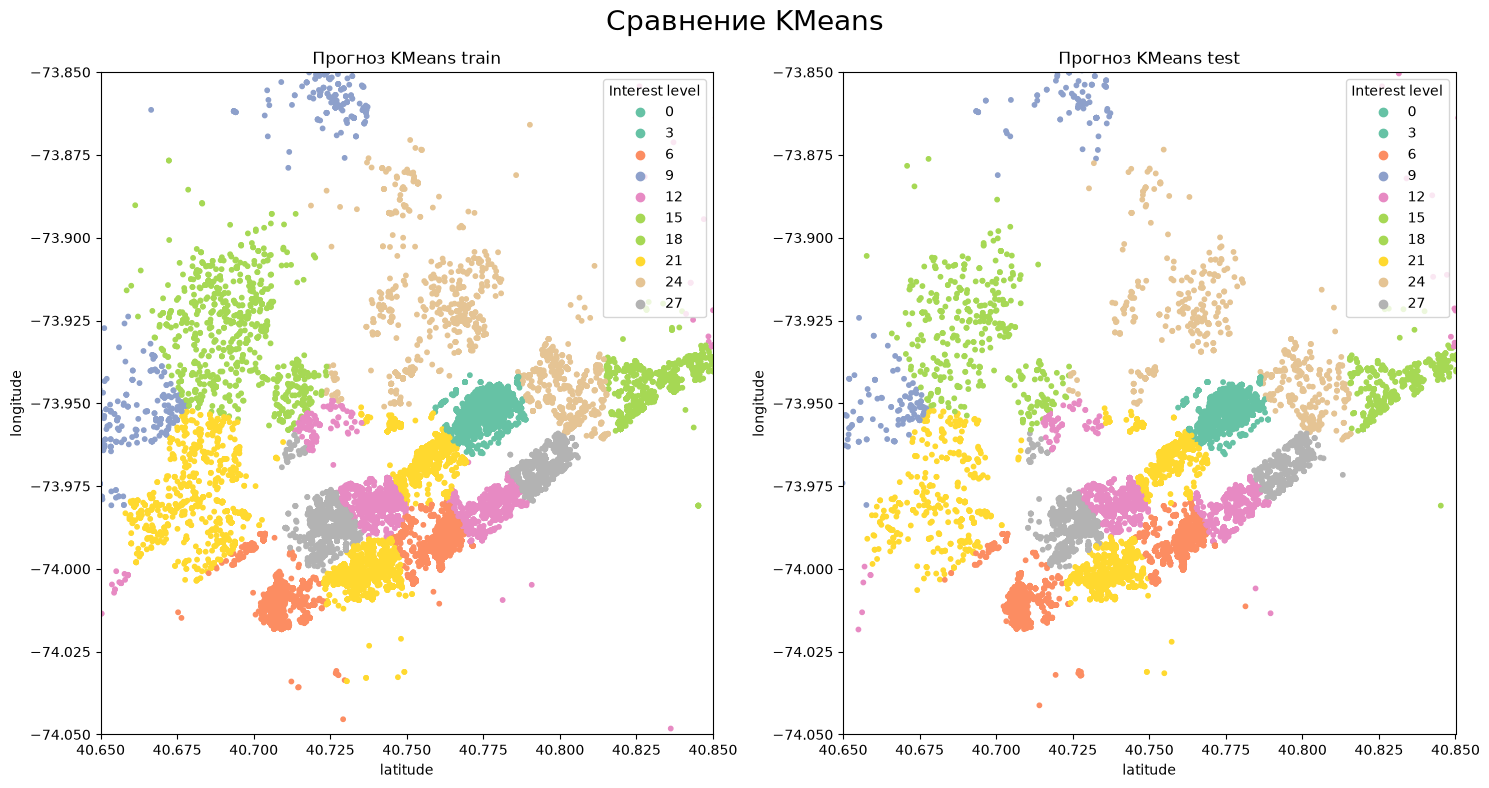

In [28]:
drow_for_longitude_latitude(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test, 'KMeans')

In [29]:
X_train['cluster'] = pred_train
X_test['cluster'] = pred_test

feature_importance, lasso_pred_train, lasso_pred_test = lasso_predict(X_train, X_test, y_train)
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'Kmeans')
feature_importance

,name,imp
5,Cats Allowed,0.000000
20,New Construction,0.000000
18,Balcony,15.051094
15,Outdoor Space,17.728801
22,Exclusive,30.142558
13,Pre-War,36.101996
10,No Fee,67.911148
6,Dogs Allowed,75.359178
19,Swimming Pool,82.731451
4,Hardwood Floors,86.679018


In [30]:
feature_importance, lasso_pred_train, lasso_pred_test = rf_predict(X_train, X_test, y_train)
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'Kmeans RandonForest')
feature_importance

,name,imp
12,Laundry In Unit,0.002912
9,Laundry In Building,0.003799
18,Balcony,0.004626
21,Terrace,0.005183
20,New Construction,0.005571
22,Exclusive,0.006102
19,Swimming Pool,0.006204
17,High Speed Internet,0.006591
14,Roof Deck,0.007504
16,Dining Room,0.007683


### DBScan

#### Как работает

Алгоритм кластеризации, который ищет плотные области в данных.\
Алгоритм:
Все точки изначально считаются шумом
1. Находим базовые точки — у которых достаточно соседей внутри eps 
2. Строим кластеры: 
* Берём базовую точку, создаём новый кластер 
* Добавляем всех её соседей (базовых и граничных) в тот же кластер 
* У соседей тоже смотрим их соседей и добавляем их 
* Повторяем, пока кластер не перестанет расти 
3. Переходим к следующей непосещённой базовой точке и повторяем шаг 3 
4. Точки, которые не вошли ни в один кластер, остаются шумом (метка -1) 

#### Код

In [31]:
class DBSCANClustering:
    def __init__(self, eps=0.5, min_samples=5, metric='euclidean', algorithm='auto', leaf_size=30):
        self.eps = eps # радиус вокруг точки
        self.min_samples = min_samples # cколько точек должно быть в радиусе eps
        self.metric = metric
        self.algorithm = algorithm
        self.leaf_size = leaf_size

    @staticmethod
    def _dbscan_inner(core_points, neighborhoods, labels):
        # номер текщего кластера и список необработанных точек
        label, queue = 0, []

        for point in range(len(core_points)):
            # назначаем базовой точке свой кластер
            if not core_points[point] or labels[point] != -1:
                continue

            labels[point] = label
            queue.append(point)

            while queue:
                # перебираем соседей для добавления в кластер
                current_point = queue.pop(0)
                if core_points[current_point]:
                    current_neighbors = neighborhoods[current_point]

                    for neighbor in current_neighbors:
                        if labels[neighbor] == -1:
                            labels[neighbor] = label
                            queue.append(neighbor)

            label += 1

    def fit_predict(self, X):
        nn = NearestNeighbors(n_neighbors=self.min_samples, radius=self.eps, metric=self.metric,
                              algorithm=self.algorithm, leaf_size=self.leaf_size)
        # ищем соседей и распределяем точки на базовые или нет
        neighborhoods = nn.fit(X).radius_neighbors(X, return_distance=False)
        labels = np.full(len(X), -1, dtype=np.intp)
        core_points = np.asarray([len(n) >= self.min_samples for n in neighborhoods])

        self._dbscan_inner(core_points, neighborhoods, labels)
        self.labels_ = labels

        return self.labels_

In [32]:
start = time.time()
dbscan = DBSCANClustering(min_samples=5, eps=0.001)
pred_train = dbscan.fit_predict(X_train_for_clusters)
pred_test = dbscan.fit_predict(X_test_for_clusters)
end = time.time()
print(f"My DBSCAN: {end - start:.5f} сек")

result_time.loc[len(result_time)] = {
        'model': 'My DBSCAN',
        'time': round(end - start, 5)
    }

My DBSCAN: 0.54428 сек


In [33]:
new_label = pred_train.max() + 1
sil_train = silhouette_score(X_train_for_clusters, np.where(pred_train == -1, new_label, pred_train))
print(f"Оценка силуэта (обучение): {sil_train}")

new_label = pred_test.max() + 1
sil_test = silhouette_score(X_test_for_clusters, np.where(pred_test == -1, new_label, pred_test))
print(f"Оценка силуэта (обучение): {sil_test}")

result_sil.loc[len(result_sil)] = {
        'model': 'My DBSCAN',
        'train': sil_train,
        'test': sil_test
    }

Оценка силуэта (обучение): -0.087938360796831
Оценка силуэта (обучение): -0.03334567861083028


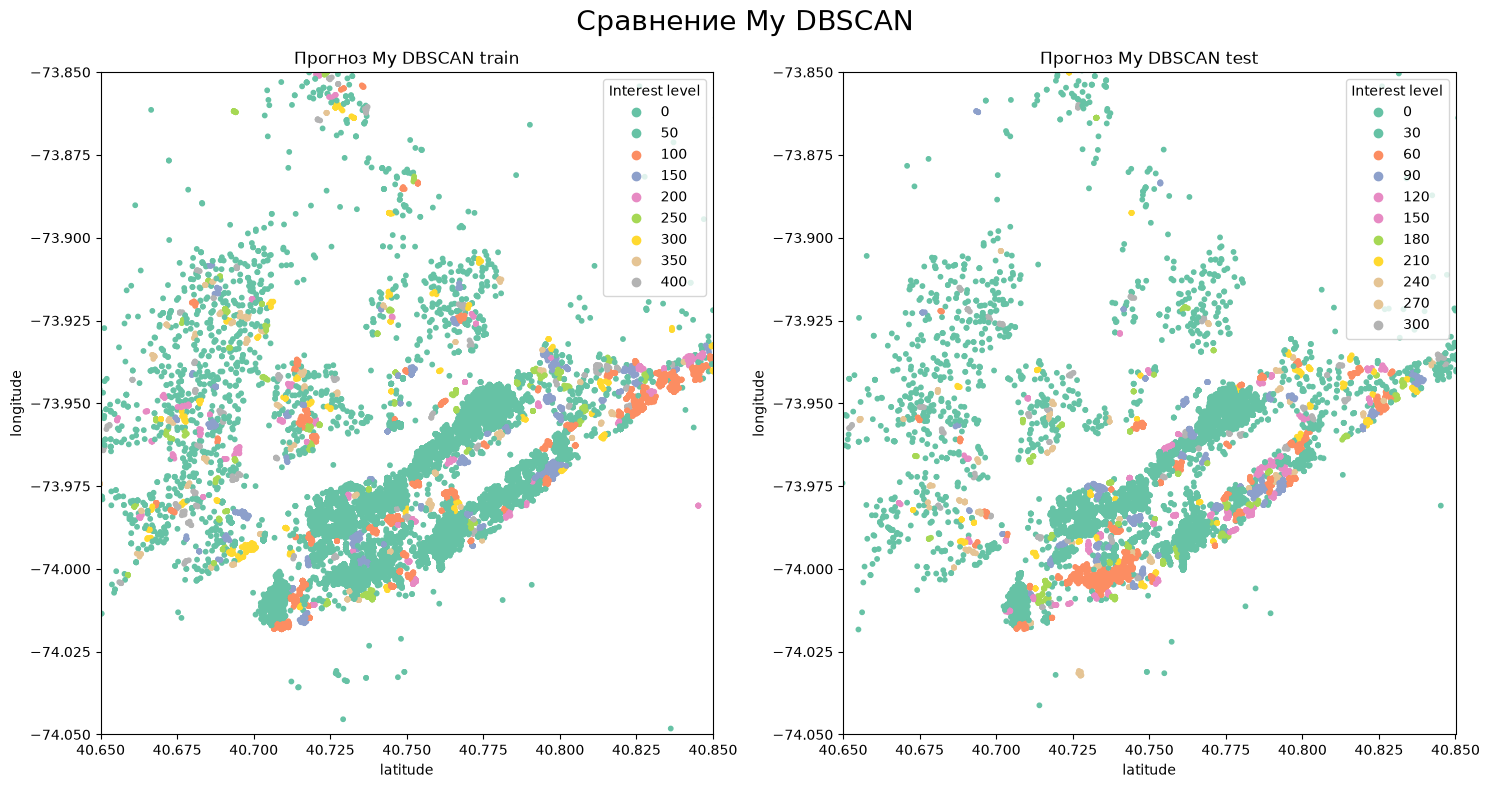

In [34]:
drow_for_longitude_latitude(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test, 'My DBSCAN')

In [35]:
X_train['cluster'] = pred_train
X_test['cluster'] = pred_test

feature_importance, lasso_pred_train, lasso_pred_test = lasso_predict(X_train, X_test, y_train)
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'My DBSCAN')
feature_importance

,name,imp
20,New Construction,0.000000
5,Cats Allowed,4.627060
15,Outdoor Space,17.453047
18,Balcony,18.103325
13,Pre-War,31.263480
22,Exclusive,38.018751
19,Swimming Pool,68.636274
10,No Fee,73.534274
6,Dogs Allowed,91.509167
4,Hardwood Floors,107.346064


In [36]:
start = time.time()
dbscan = DBSCAN(min_samples=5, eps=0.001, metric='euclidean')
pred_train = dbscan.fit_predict(X_train_for_clusters)
pred_test = dbscan.fit_predict(X_test_for_clusters)
end = time.time()
print(f"My DBSCAN: {end - start:.5f} сек")

result_time.loc[len(result_time)] = {
        'model': 'DBSCAN',
        'time': round(end - start, 5)
    }

My DBSCAN: 0.27135 сек


In [37]:
new_label = pred_train.max() + 1
sil_train = silhouette_score(X_train_for_clusters, np.where(pred_train == -1, new_label, pred_train))
print(f"Оценка силуэта (обучение): {sil_train}")

new_label = pred_test.max() + 1
sil_test = silhouette_score(X_test_for_clusters, np.where(pred_test == -1, new_label, pred_test))
print(f"Оценка силуэта (обучение): {sil_test}")

result_sil.loc[len(result_sil)] = {
        'model': 'DBSCAN',
        'train': sil_train,
        'test': sil_test
    }

Оценка силуэта (обучение): -0.087938360796831
Оценка силуэта (обучение): -0.03334567861083028


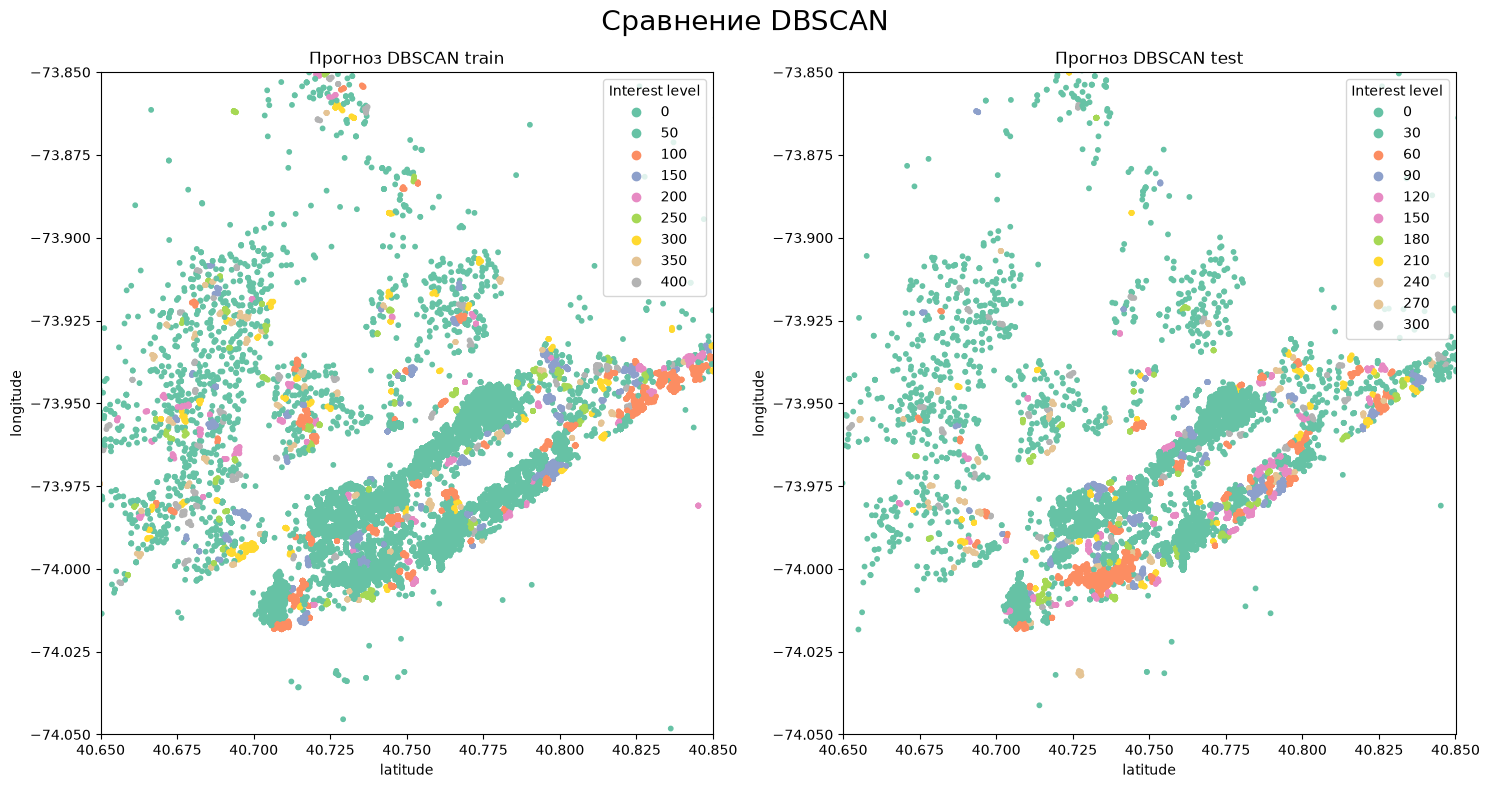

In [38]:
drow_for_longitude_latitude(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test, 'DBSCAN')

In [39]:
X_train['cluster'] = pred_train
X_test['cluster'] = pred_test

feature_importance, lasso_pred_train, lasso_pred_test = lasso_predict(X_train, X_test, y_train)
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'DBSCAN')
feature_importance

,name,imp
20,New Construction,0.000000
5,Cats Allowed,4.627060
15,Outdoor Space,17.453047
18,Balcony,18.103325
13,Pre-War,31.263480
22,Exclusive,38.018751
19,Swimming Pool,68.636274
10,No Fee,73.534274
6,Dogs Allowed,91.509167
4,Hardwood Floors,107.346064


In [40]:
feature_importance, lasso_pred_train, lasso_pred_test = rf_predict(X_train, X_test, y_train)
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'DBSCAN RandomForest')
feature_importance

,name,imp
12,Laundry In Unit,0.002740
9,Laundry In Building,0.003879
18,Balcony,0.004170
20,New Construction,0.004447
21,Terrace,0.005471
22,Exclusive,0.006091
19,Swimming Pool,0.006300
17,High Speed Internet,0.007361
14,Roof Deck,0.007413
16,Dining Room,0.007994


### AgglomerativeClustering

#### Как работает

Иерархическая кластеризация снизу вверх.

Сначала каждая точка — это отдельный кластер. Затем на каждом шаге два самых похожих кластера объединяются в один. Процесс повторяется, пока не останется нужное количество кластеров.

#### Применение

In [41]:
start = time.time()
clustering = AgglomerativeClustering(n_clusters=30)
pred_train = clustering.fit_predict(X_train_for_clusters)
pred_test = clustering.fit_predict(X_test_for_clusters)
end = time.time()
print(f"KMeans: {end - start:.5f} сек")

result_time.loc[len(result_time)] = {
        'model': 'AgglomerativeClustering',
        'time': round(end - start, 5)
    }

KMeans: 54.15125 сек


In [42]:
result_sil = silsil(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test, result_sil, 'AgglomerativeClustering')

Оценка силуэта (обучение): 0.45856414134515805
Оценка силуэта (тест): 0.45328368242814127


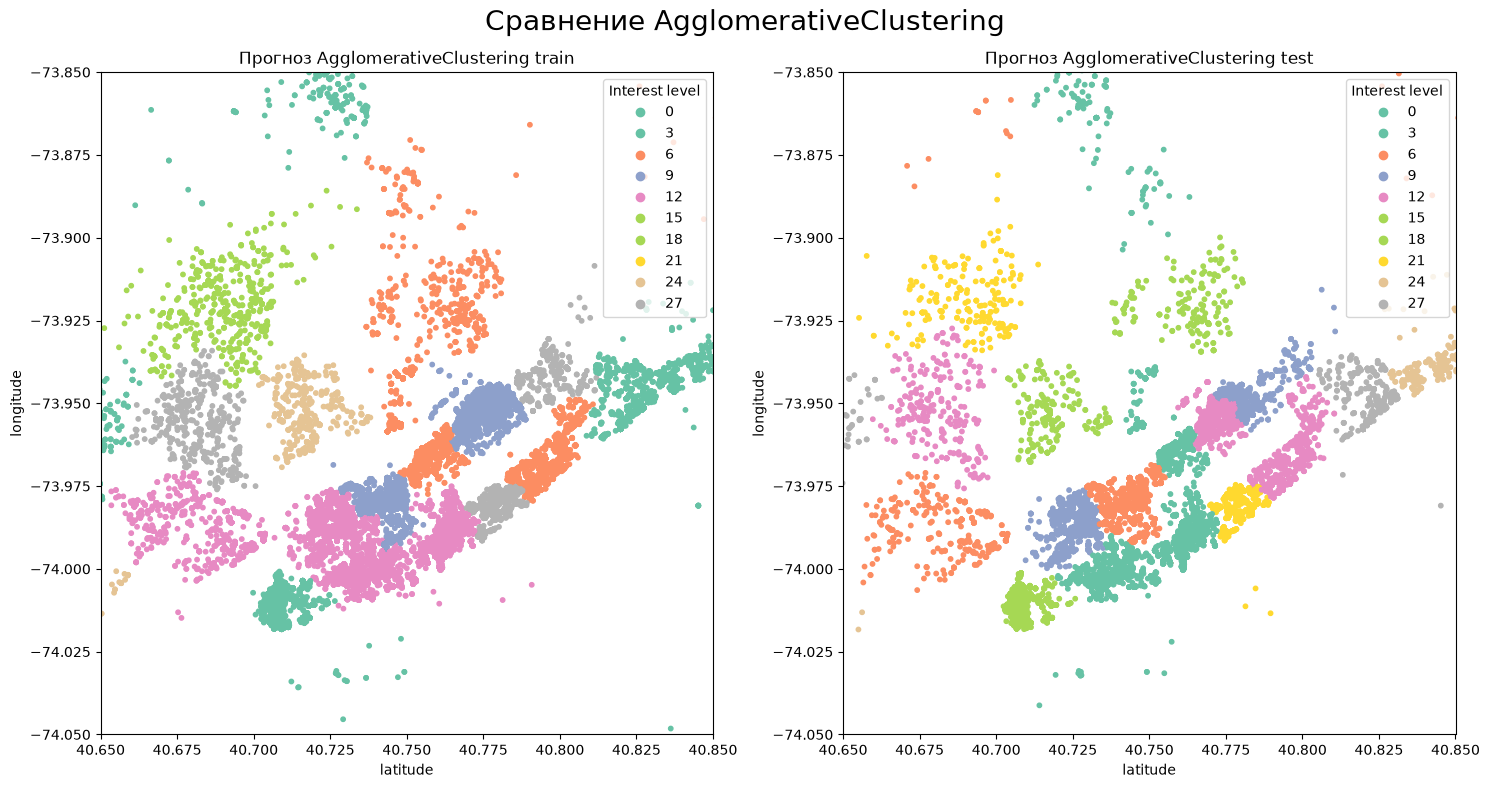

In [43]:
drow_for_longitude_latitude(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test, 'AgglomerativeClustering')

In [44]:
X_train['cluster'] = pred_train
X_test['cluster'] = pred_test

feature_importance, lasso_pred_train, lasso_pred_test = lasso_predict(X_train, X_test, y_train)
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'AgglomerativeClustering')
feature_importance

,name,imp
20,New Construction,0.000000
5,Cats Allowed,3.126401
18,Balcony,15.666998
15,Outdoor Space,20.256497
22,Exclusive,27.421706
13,Pre-War,30.691721
19,Swimming Pool,55.770372
10,No Fee,75.698469
6,Dogs Allowed,84.164972
4,Hardwood Floors,93.492761


In [45]:
feature_importance, lasso_pred_train, lasso_pred_test = rf_predict(X_train, X_test, y_train)
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'AgglomerativeClustering RandomForest')
feature_importance

,name,imp
12,Laundry In Unit,0.002740
9,Laundry In Building,0.003932
18,Balcony,0.004402
20,New Construction,0.004981
21,Terrace,0.005227
22,Exclusive,0.006310
19,Swimming Pool,0.006702
15,Outdoor Space,0.007191
14,Roof Deck,0.007267
17,High Speed Internet,0.007480


### GaussianMixture

#### Как работает

В GMM точка с вероятностью принадлежит каждому кластеру. Например: "точка с вероятностью 70% принадлежит кластеру А, с 30% — кластеру Б".

#### Применение

In [46]:
start = time.time()
gm = GaussianMixture(n_components=30, random_state=21).fit(X_train_for_clusters)
pred_train = gm.predict(X_train_for_clusters)
pred_test = gm.predict(X_test_for_clusters)
end = time.time()
print(f"KMeans: {end - start:.5f} сек")

result_time.loc[len(result_time)] = {
        'model': 'GaussianMixture',
        'time': round(end - start, 5)
    }

KMeans: 1.34857 сек


In [47]:
result_sil = silsil(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test, result_sil, 'GaussianMixture')

Оценка силуэта (обучение): 0.40612187042898257
Оценка силуэта (тест): 0.40195464025344485


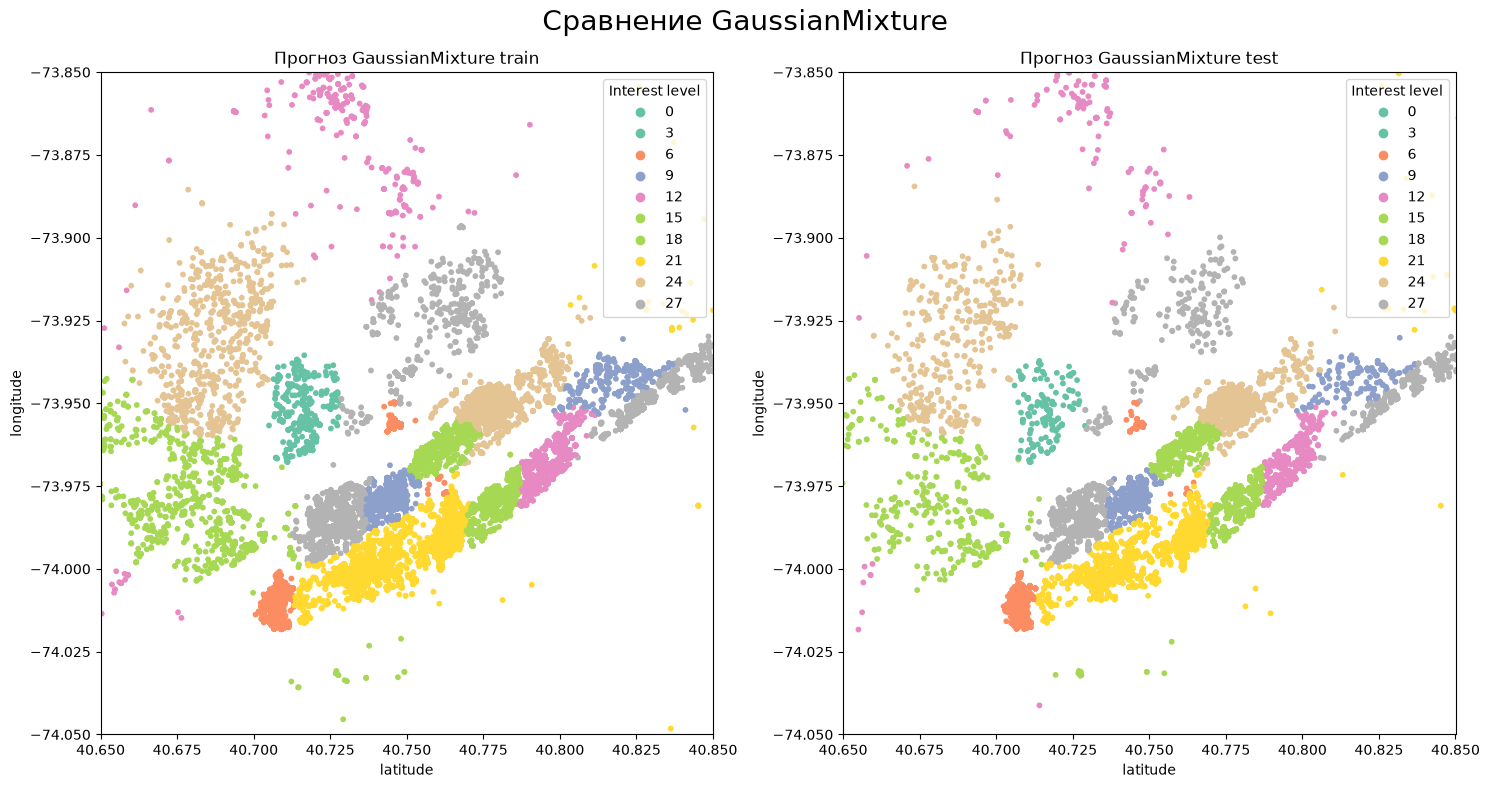

In [48]:
drow_for_longitude_latitude(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test, 'GaussianMixture')

In [49]:
X_train['cluster'] = pred_train
X_test['cluster'] = pred_test

feature_importance, lasso_pred_train, lasso_pred_test = lasso_predict(X_train, X_test, y_train)
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'GaussianMixture')
feature_importance

,name,imp
20,New Construction,0.000000
5,Cats Allowed,3.598959
18,Balcony,14.120027
15,Outdoor Space,16.584570
23,cluster,22.019251
13,Pre-War,32.456159
22,Exclusive,34.858168
19,Swimming Pool,62.209539
10,No Fee,75.431565
6,Dogs Allowed,85.611121


In [50]:
feature_importance, lasso_pred_train, lasso_pred_test = rf_predict(X_train, X_test, y_train)
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'GaussianMixture RandomForest')
feature_importance

,name,imp
12,Laundry In Unit,0.002744
9,Laundry In Building,0.003675
18,Balcony,0.004699
21,Terrace,0.005066
20,New Construction,0.005447
17,High Speed Internet,0.006124
22,Exclusive,0.006209
19,Swimming Pool,0.006212
14,Roof Deck,0.006951
15,Outdoor Space,0.007395


## Результаты на других признаках

In [51]:
def drow_for_3d(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test, name):
    fig = plt.figure(figsize=(16, 9))
    
    ax1 = fig.add_subplot(1, 2, 1, projection='3d')
    sc1 = ax1.scatter(X_train_for_clusters.iloc[:, 0], 
                      X_train_for_clusters.iloc[:, 1], 
                      X_train_for_clusters.iloc[:, 2],
                      c=pred_train, s=20, cmap='Set2', alpha=0.6)
    ax1.set_xlabel('interest_level')
    ax1.set_ylabel('bedrooms')
    ax1.set_zlabel('bathrooms')
    ax1.set_title(f'Прогноз {name} train')
    ax1.legend(*sc1.legend_elements(),
               loc='upper right')
    # plt.colorbar(sc1, ax=ax1, label='Кластер')
    
    ax2 = fig.add_subplot(1, 2, 2, projection='3d')
    sc2 = ax2.scatter(X_test_for_clusters.iloc[:, 0], 
                      X_test_for_clusters.iloc[:, 1], 
                      X_test_for_clusters.iloc[:, 2],
                      c=pred_test, s=20, cmap='Set2', alpha=0.6)
    ax2.set_xlabel('interest_level')
    ax2.set_ylabel('bedrooms')
    ax2.set_zlabel('bathrooms')
    ax2.set_title(f'Прогноз {name} test')
    ax2.legend(*sc2.legend_elements(),
               loc='upper right')
    # plt.colorbar(sc2, ax=ax2, label='Кластер')
    
    fig.suptitle(f'{name} кластеризация (interest_level, bedrooms, bathrooms)', fontsize=16)
    plt.tight_layout()
    plt.show()

In [52]:
X_train_for_clusters = X_train_temp_clusters[['interest_level','bedrooms', 'bathrooms']]
X_test_for_clusters = X_test_temp_clusters[['interest_level','bedrooms', 'bathrooms']]

### KMeans

In [53]:
cluster_model = KMeans(n_clusters=30, random_state=42)
cluster_model.fit(X_train_for_clusters)
pred_train = cluster_model.predict(X_train_for_clusters)
pred_test_kmeans = cluster_model.predict(X_test_for_clusters)

In [54]:
distortion = cluster_model.inertia_
print(f"Искажение (инерция): {distortion}")

result_sil = silsil(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test_kmeans, result_sil, 'KMeans')

Искажение (инерция): 509.6005099892618
Оценка силуэта (обучение): 0.9575895091142308
Оценка силуэта (тест): 0.9572277987618111


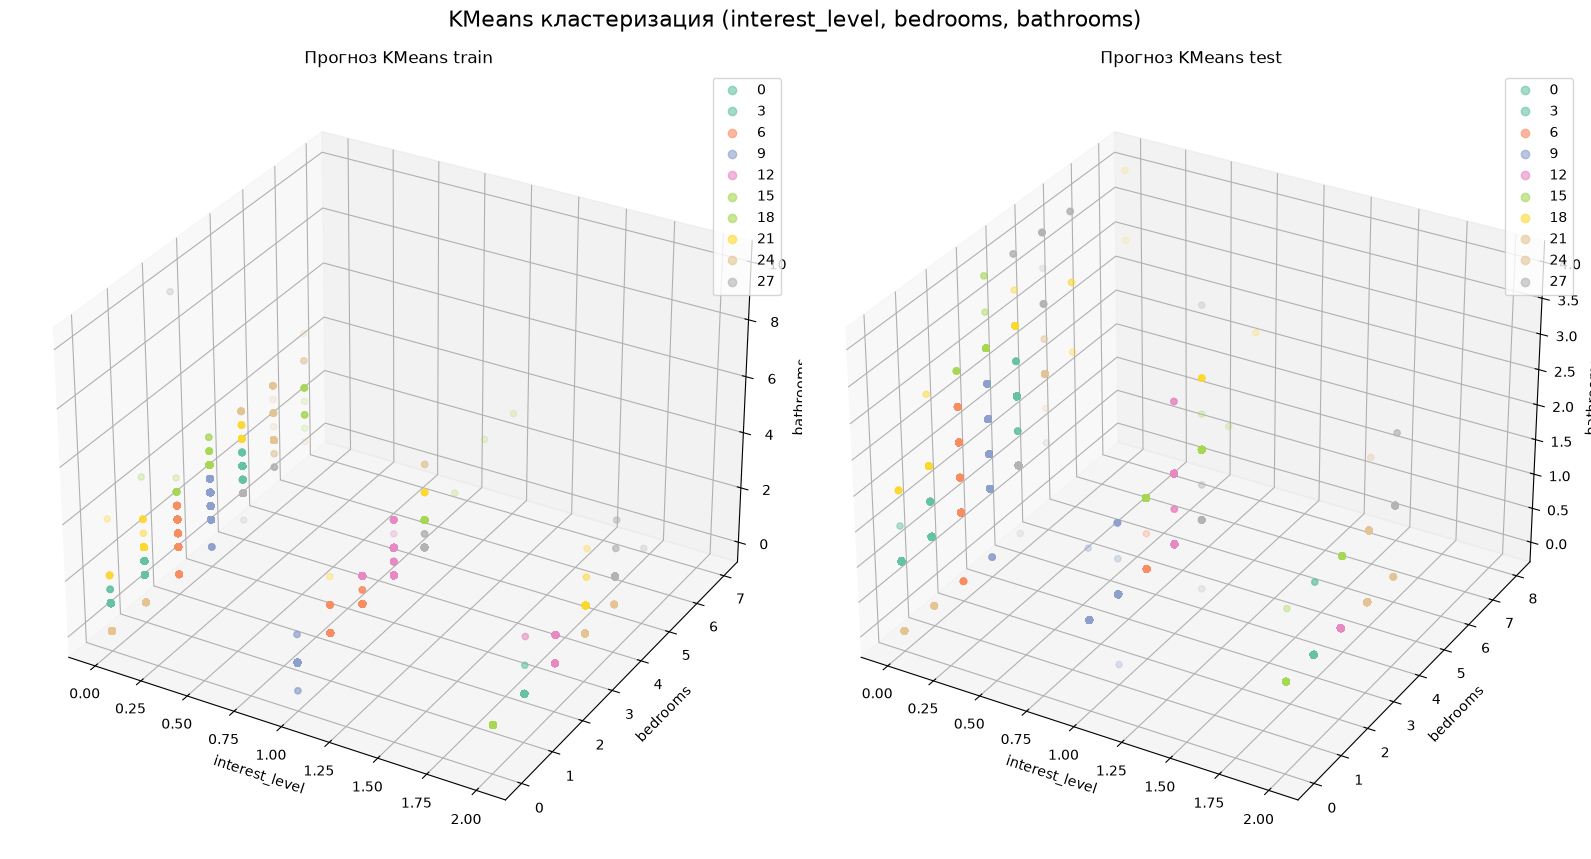

In [55]:
drow_for_3d(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test_kmeans, 'KMeans')

In [56]:
X_train['cluster'] = pred_train
X_test['cluster'] = pred_test_kmeans

feature_importance, lasso_pred_train, lasso_pred_test = lasso_predict(X_train, X_test, y_train)
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'KMeans + features')
feature_importance

,name,imp
5,Cats Allowed,0.000000
20,New Construction,0.000000
18,Balcony,14.332025
15,Outdoor Space,15.990609
22,Exclusive,26.879555
13,Pre-War,29.837046
19,Swimming Pool,66.680877
10,No Fee,79.718910
6,Dogs Allowed,88.875344
4,Hardwood Floors,91.595075


### DBSCAN

In [57]:
dbscan = DBSCAN(min_samples=5, eps=0.001, metric='euclidean')
pred_train = dbscan.fit_predict(X_train_for_clusters)
pred_test_dbscan = dbscan.fit_predict(X_test_for_clusters)

In [58]:
new_label = pred_train.max() + 1
sil_train = silhouette_score(X_train_for_clusters, np.where(pred_train == -1, new_label, pred_train))
print(f"Оценка силуэта (обучение): {sil_train}")

new_label = pred_test.max() + 1
sil_test = silhouette_score(X_test_for_clusters, np.where(pred_test_dbscan == -1, new_label, pred_test_dbscan))
print(f"Оценка силуэта (обучение): {sil_test}")

result_sil.loc[len(result_sil)] = {
        'model': 'DBSCAN',
        'train': sil_train,
        'test': sil_test
    }

Оценка силуэта (обучение): 0.9975220822157498
Оценка силуэта (обучение): 0.9933847331119275


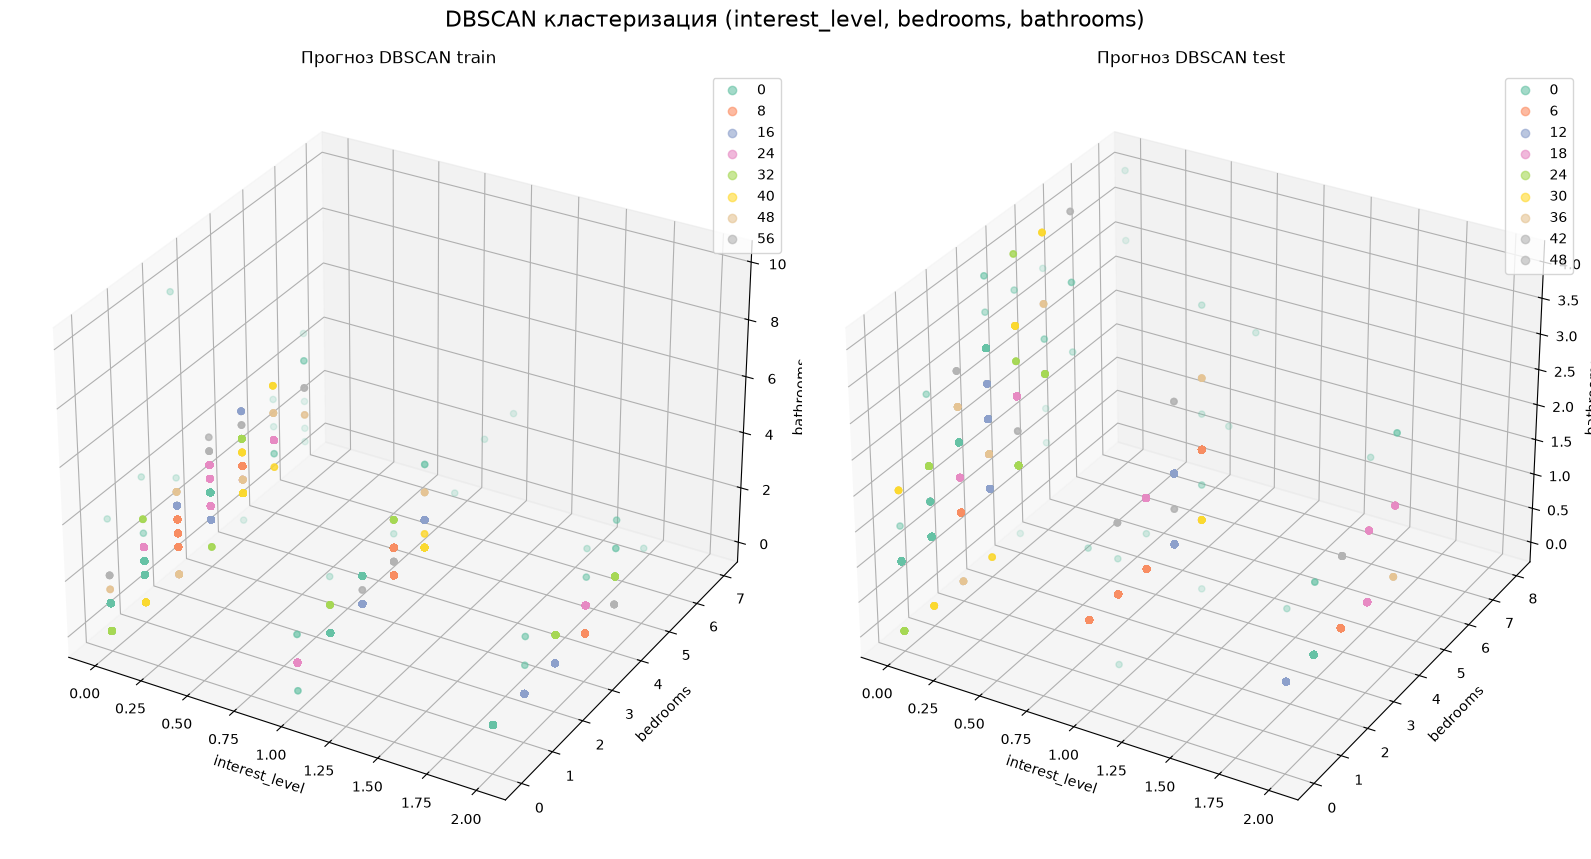

In [59]:
drow_for_3d(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test_dbscan, 'DBSCAN')

In [60]:
X_train['cluster'] = pred_train
X_test['cluster'] = pred_test_dbscan

feature_importance, lasso_pred_train, lasso_pred_test = lasso_predict(X_train, X_test, y_train)
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'DBSCAN + features')
feature_importance

,name,imp
5,Cats Allowed,0.000000
20,New Construction,0.000000
18,Balcony,11.900452
15,Outdoor Space,15.819147
13,Pre-War,26.527340
22,Exclusive,27.659544
19,Swimming Pool,62.529849
10,No Fee,80.031107
4,Hardwood Floors,88.280777
6,Dogs Allowed,91.379840


### AgglomerativeClustering

In [61]:
clustering = AgglomerativeClustering(n_clusters=30)
pred_train = clustering.fit_predict(X_train_for_clusters)
pred_test_ac = clustering.fit_predict(X_test_for_clusters)

In [62]:
result_sil = silsil(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test_ac, result_sil, 'AgglomerativeClustering')

Оценка силуэта (обучение): 0.9622099738432525
Оценка силуэта (тест): 0.9619063588001537


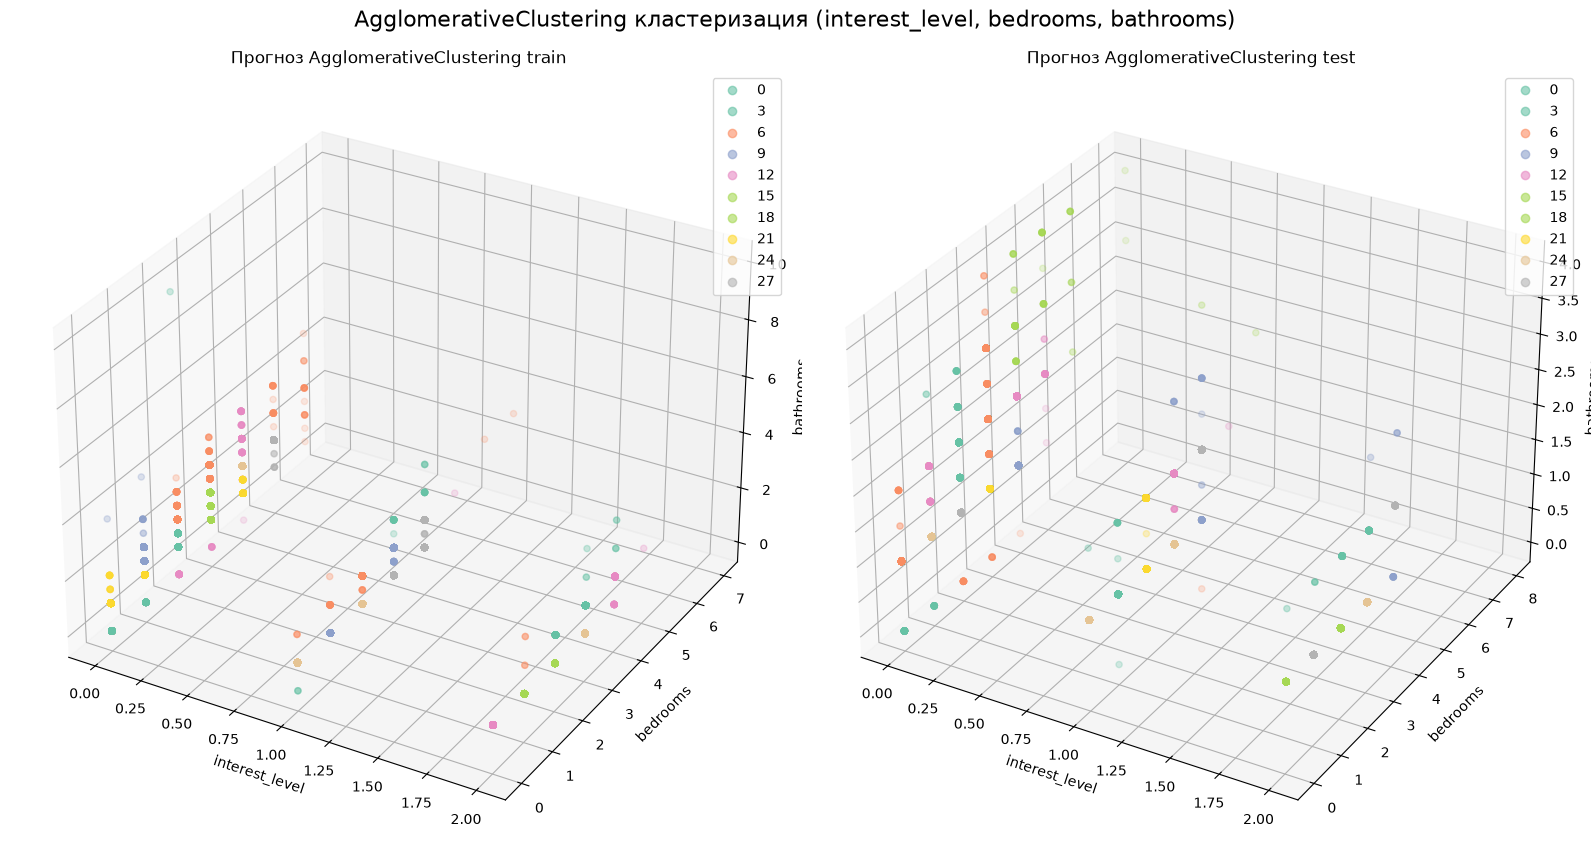

In [63]:
drow_for_3d(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test_ac, 'AgglomerativeClustering')

In [64]:
X_train['cluster'] = pred_train
X_test['cluster'] = pred_test_ac

feature_importance, lasso_pred_train, lasso_pred_test = lasso_predict(X_train, X_test, y_train)
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'AgglomerativeClustering + features')
feature_importance

,name,imp
20,New Construction,0.000000
5,Cats Allowed,3.882805
23,cluster,6.881133
18,Balcony,14.125127
15,Outdoor Space,16.880820
13,Pre-War,31.978931
22,Exclusive,34.876111
19,Swimming Pool,60.904107
10,No Fee,75.272086
6,Dogs Allowed,86.004896


### GaussianMixture

In [65]:
gm = GaussianMixture(n_components=30, random_state=21).fit(X_train_for_clusters)
pred_train = gm.predict(X_train_for_clusters)
pred_test_gm = gm.predict(X_test_for_clusters)

In [66]:
result_sil = silsil(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test_gm, result_sil, 'GaussianMixture')

Оценка силуэта (обучение): 0.9545685701278664
Оценка силуэта (тест): 0.9545873114067788


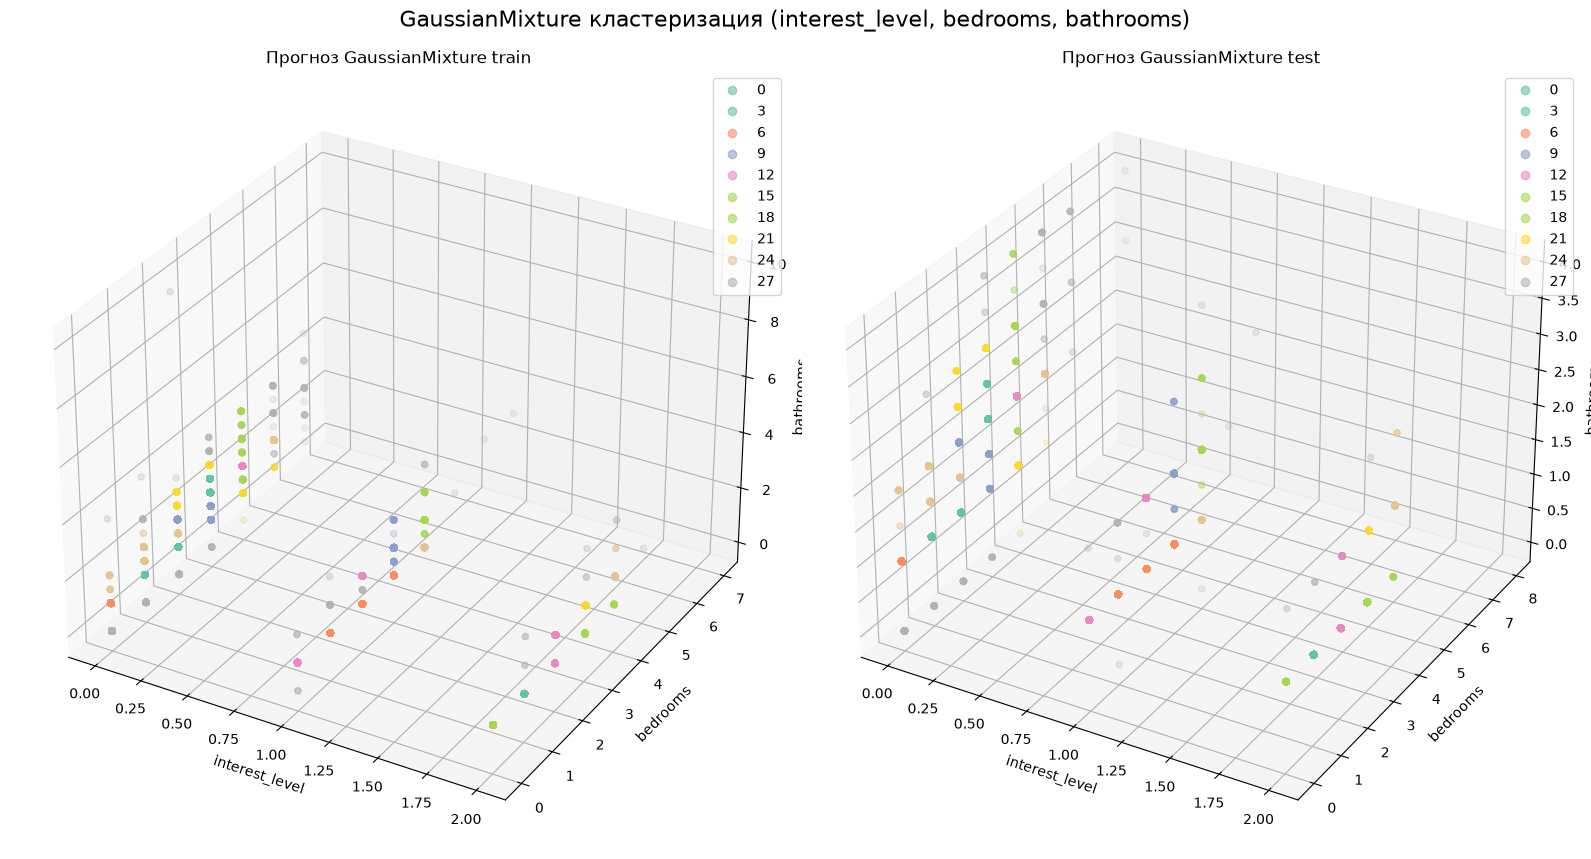

In [67]:
drow_for_3d(X_train_for_clusters, pred_train, X_test_for_clusters, pred_test_gm, 'GaussianMixture')

In [68]:
X_train['cluster'] = pred_train
X_test['cluster'] = pred_test_gm

feature_importance, lasso_pred_train, lasso_pred_test = lasso_predict(X_train, X_test, y_train)
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'GaussianMixture + features')
feature_importance

,name,imp
20,New Construction,0.000000
5,Cats Allowed,1.394447
18,Balcony,7.247344
15,Outdoor Space,13.763553
22,Exclusive,18.418233
13,Pre-War,22.895076
19,Swimming Pool,62.801373
10,No Fee,82.146131
4,Hardwood Floors,83.854893
6,Dogs Allowed,97.499538


### Оценка результата

**СЛОЖНОСТЬ**

***K‑Means***\
Сложность: O(n × k × iter), где n — количество точек, k — число кластеров, iter — число итераций.\
\
Время работы растёт линейно с увеличением количества точек. На практике K‑Means считается одним из самых быстрых алгоритмов кластеризации. Даже при большом k (например, 30) и нескольких сотнях итераций он завершается за секунды или десятки секунд.\
\
\
***DBSCAN***\
В худшем случае O(n²), но при использовании пространственных индексов (например, KD‑дерево или Ball‑tree) — O(n log n).\

DBSCAN требует вычисления попарных расстояний или эффективного поиска соседей в радиусе eps. При росте количества точек до 50 000 и более производительность может сильно упасть, особенно если данные не позволяют эффективно использовать индексы. На практике DBSCAN заметно медленнее K‑Means на больших выборках.\
\
\
***Agglomerative***\
O(n³) в наивной реализации, оптимизированные версии — около O(n² log n) или O(n²).\
\
Это самый медленный из перечисленных методов. Уже на 5 000–10 000 точках время работы становится очень большим, поэтому на практике его применяют либо на небольших выборках, либо с использованием приближённых методов или обрезания дендрограммы.\
\
\
***Gaussian Mixture Model***\
O(n × k × iter), аналогично K‑Means, но с дополнительными затратами на работу с ковариационными матрицами (особенно при covariance_type='full').\
\
По скорости GMM близок к K‑Means, но обычно работает в несколько раз медленнее, так как на каждом шаге нужно вычислять не только расстояния, но и вероятности с учётом формы кластеров.

**СКОРОСТЬ**

In [69]:
result_time

,model,time
0,My KMeans,0.25140
1,KMeans,0.17227
2,My DBSCAN,0.54428
3,DBSCAN,0.27135
4,AgglomerativeClustering,54.15125
5,GaussianMixture,1.34857


AgglomerativeClustering занял почти 40 секунд, что в сотни раз медленнее остальных. Это связано с его квадратичной сложностью, и на больших данных он практически неприменим.

**ТОЧНОСТЬ**

In [70]:
result_sil

,model,train,test
0,My KMeans,0.409049,0.409675
1,KMeans,0.451240,0.457018
2,My DBSCAN,-0.087938,-0.033346
3,DBSCAN,-0.087938,-0.033346
4,AgglomerativeClustering,0.458564,0.453284
5,GaussianMixture,0.406122,0.401955
6,KMeans,0.957590,0.957228
7,DBSCAN,0.997522,0.993385
8,AgglomerativeClustering,0.962210,0.961906
9,GaussianMixture,0.954569,0.954587


Все методы показали неплохую кластеризацию (силуэт 0,4–0,46). Это нормально для географических данных, они плавно переходят друг в друга. DBSCAN не справился: отрицательный силуэт означает, что при выбранных параметрах (min_samples=5, eps=0.001) алгоритм не смог выделить кластеры и пометил большинство точек как шум.\
На признаках interest_level, bedrooms, bathrooms все методы показали отличную кластеризацию. Это говорит о том, что данные естественным образом разбиваются на плотные, хорошо разделённые группы. Разница между методами минимальна, любой из них даёт почти идеальный результат.

In [71]:
result_MAE

,model,train,test
0,Изначальный,699.264490,690.452932
1,Мой Kmeans,697.632527,687.927663
2,Kmeans,693.267159,683.973917
3,Kmeans RandonForest,271.207512,448.798071
4,My DBSCAN,695.319859,693.328292
5,DBSCAN,695.319859,693.328292
6,DBSCAN RandomForest,251.114311,703.791480
7,AgglomerativeClustering,698.269317,697.226981
8,AgglomerativeClustering RandomForest,270.454243,917.051146
9,GaussianMixture,699.242041,690.420380


In [72]:
result_RMSE

,model,train,test
0,Изначальный,1015.030667,994.049486
1,Мой Kmeans,1011.285682,990.031461
2,Kmeans,1011.110510,990.439630
3,Kmeans RandonForest,455.351616,741.126537
4,My DBSCAN,1011.291532,998.992844
5,DBSCAN,1011.291532,998.992844
6,DBSCAN RandomForest,421.669101,1019.286277
7,AgglomerativeClustering,1014.260315,1001.993413
8,AgglomerativeClustering RandomForest,455.860524,1299.210375
9,GaussianMixture,1014.997415,994.014514


In [73]:
result_r2

,model,train,test
0,Изначальный,0.591636,0.603679
1,Мой Kmeans,0.594644,0.606877
2,Kmeans,0.594784,0.606553
3,Kmeans RandonForest,0.917817,0.779700
4,My DBSCAN,0.594639,0.599728
5,DBSCAN,0.594639,0.599728
6,DBSCAN RandomForest,0.929525,0.583301
7,AgglomerativeClustering,0.592256,0.597320
8,AgglomerativeClustering RandomForest,0.917633,0.322999
9,GaussianMixture,0.591663,0.603707


## Бонус

Модель Random Forest была добавлена в качестве эксперимента и показала результат на выборке больше, чем Lasso. Но без подобранных параметров она показывает нестабильные результаты.

#### 1

In [74]:
result_r2

,model,train,test
0,Изначальный,0.591636,0.603679
1,Мой Kmeans,0.594644,0.606877
2,Kmeans,0.594784,0.606553
3,Kmeans RandonForest,0.917817,0.779700
4,My DBSCAN,0.594639,0.599728
5,DBSCAN,0.594639,0.599728
6,DBSCAN RandomForest,0.929525,0.583301
7,AgglomerativeClustering,0.592256,0.597320
8,AgglomerativeClustering RandomForest,0.917633,0.322999
9,GaussianMixture,0.591663,0.603707


#### 2

In [75]:
X_val, X_train, y_val, y_train = train_test_split(X_train, y_train, test_size=0.85, random_state=21)

In [78]:
best_k = 2
best_sil = -1
best_r2 = -100
for k in [5, 10, 30, 50, 100]:
    start = time.time()
    kmeans = KMeans(n_clusters=k, random_state=42)
    pred = kmeans.fit_predict(X_train_for_clusters.head(5076)) # X_val.shape (5076, 23)
    end = time.time()
    sil = silhouette_score(X_train_for_clusters.head(5076), pred)
    print(f"Lead time: {end-start:.4f}")
    X_val['cluster'] = pred
    feature_importance, pred_val, pred_test = rf_predict(X_val, None, y_val)
    r2 = r2_score(y_val, pred_val)
    print(f"k={k}, silhouette={sil:.4f}, r2: {r2:.4f}")
    if r2 > best_r2:
        best_r2 = r2
        best_sil = sil
        best_k = k

print(f"Оптимальное k: {best_k}, силуэт: {best_sil:.4f}, r2: {best_r2:.4f}")

Lead time: 0.0384
k=5, silhouette=0.5006, r2: 0.8867
Lead time: 0.0109
k=10, silhouette=0.7299, r2: 0.9007
Lead time: 0.0152
k=30, silhouette=0.9660, r2: 0.9139
Lead time: 0.0199
k=50, silhouette=0.9923, r2: 0.9139


/home/user/school21/virt/lib/python3.14/site-packages/sklearn/base.py:1403: ConvergenceWarning: Number of distinct clusters (66) found smaller than n_clusters (100). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


Lead time: 0.0248
k=100, silhouette=0.9963, r2: 0.9146
Оптимальное k: 100, силуэт: 0.9963, r2: 0.9146


Лучший параметр k, который описывает на сколько кластеров разделяется выборка, не может быть гарантировано определен.\
\
Если рассматривать только оценку модели Случайного леса, то можно увидеть наилучший результат при k=100. Но, зная как устроено дерево, можно легко предположить почему так происзодит.\
Моё мнение, что из совокупности нескольких метрик, нужно выбрать k=30. Силуэт наивысший, но и модель показывает высокий уровень.

#### 3

In [79]:
if 'cluster' in df.columns: X_test = X_test.drop(columns='cluster')
X_test['cluster_kmeans'] = pred_test_kmeans
X_test['cluster_dbscan'] = pred_test_dbscan
X_test['cluster_agg'] = pred_test_ac
X_test['cluster_gmm'] = pred_test_gm

In [80]:
feature_importance, pred_test, pred = rf_predict(X_test, None, y_test)
r2 = r2_score(y_test, pred_test)
print(f"r2 score: {r2:.4f}")

r2 score: 0.8261


# NADO

!git add ml7.ipynb
!git commit -m "Бонуска, несколько кластеров в выборке"
!git push origin develop

lasso = Lasso(random_state=21)
lasso.fit(X_train, y_train)
lasso_pred_train = lasso.predict(X_train)
lasso_pred_test = lasso.predict(X_test)
result_MAE, result_RMSE, result_r2 = metrics(result_MAE, result_RMSE, result_r2, y_train, lasso_pred_train, y_test, lasso_pred_test, 'Мой Kmeans')
columns_name = X_train.columns
feature_importance = pd.DataFrame()
feature_importance['name'] = columns_name
feature_importance['imp'] = abs(lasso.coef_)
feature_importance = feature_importance.sort_values('imp')
feature_importance